In [51]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

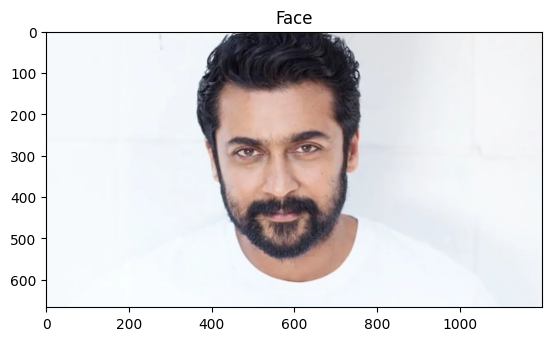

In [61]:

faceImage = cv2.imread('actor_photo.jpg')
plt.imshow(faceImage[:, :, ::-1])
plt.title("Face")



In [53]:
faceImage.shape

(667, 1200, 3)

In [54]:

faceImage.shape

(667, 1200, 3)

Text(0.5, 1.0, 'glassPNG')

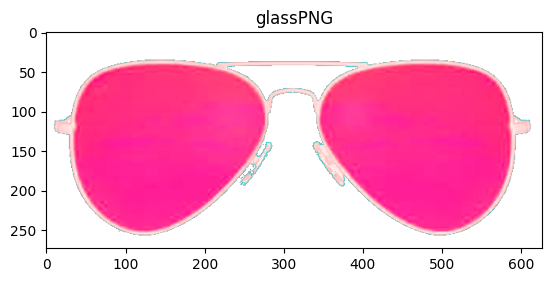

In [55]:

# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [56]:

glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [27]:

glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

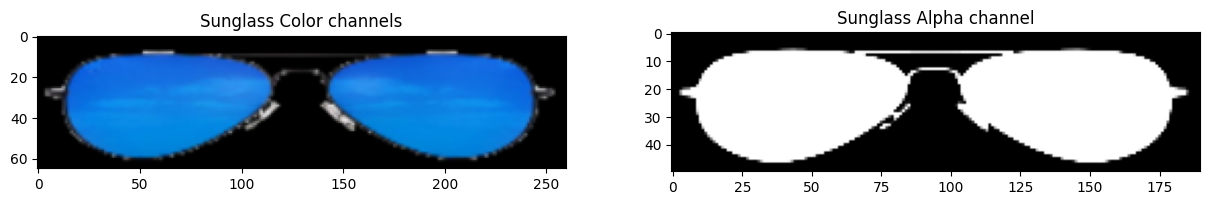

In [57]:

plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

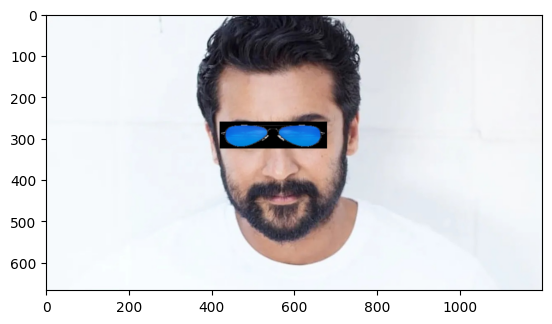

In [63]:
faceWithGlassesNaive = faceImage.copy()
faceWithGlassesNaive[260:325, 420:680]=glassBGR
plt.imshow(faceWithGlassesNaive[...,::-1])

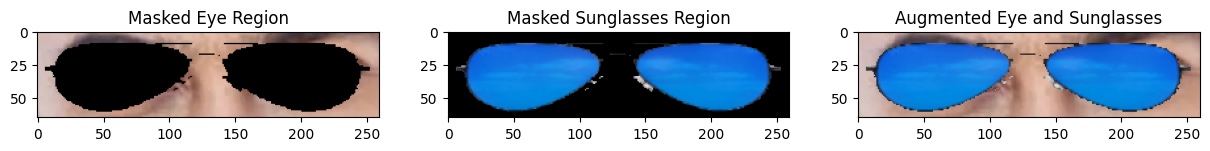

In [65]:
# import cv2
import numpy as np
import matplotlib.pyplot as plt
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))
glassMask = np.uint8(glassMask / 255)
faceWithGlassesArithmetic = faceImage.copy()
glassBGR = cv2.resize(glassBGR, (260, 65))
glassMask = cv2.resize(glassMask, (260, 65))
eyeROI = faceWithGlassesArithmetic[255:320, 420:680]
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)
maskedGlass = cv2.multiply(glassBGR[:, :, :3], glassMask)
eyeROI_final = cv2.add(maskedEye, maskedGlass)
plt.figure(figsize=(15, 10))
plt.subplot(131)
plt.imshow(maskedEye[:, :, ::-1])
plt.title("Masked Eye Region")
plt.subplot(132)
plt.imshow(maskedGlass[:, :, ::-1])
plt.title("Masked Sunglasses Region")
plt.subplot(133)
plt.imshow(eyeROI_final[:, :, ::-1])
plt.title("Augmented Eye and Sunglasses")
plt.show()

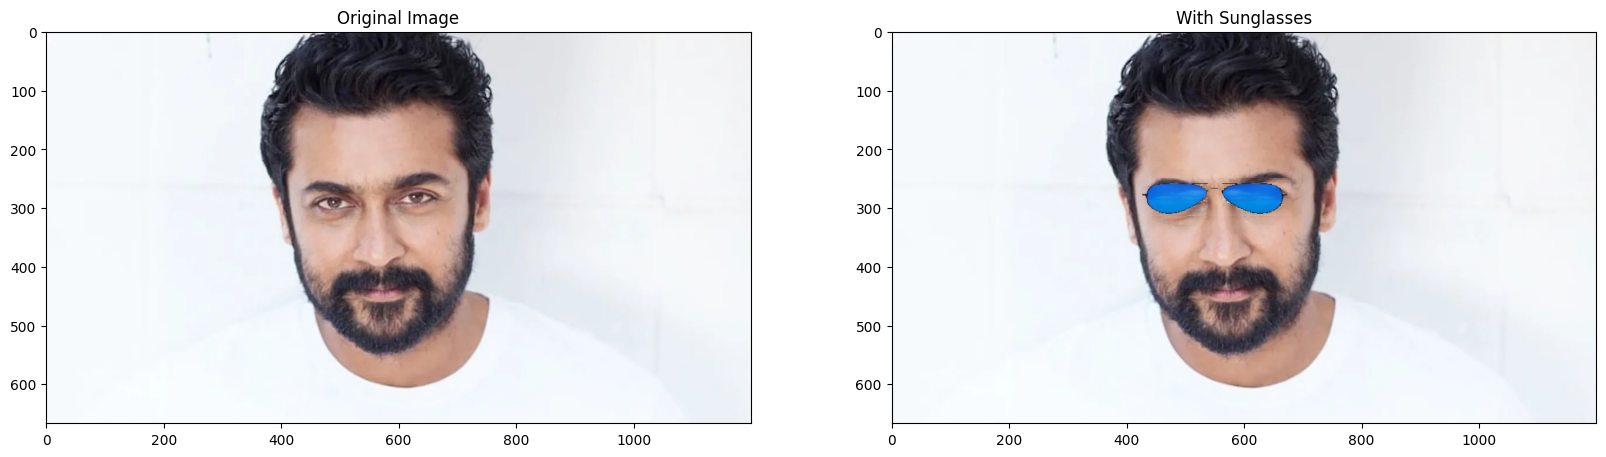

In [66]:
faceWithGlassesArithmetic[250:315, 420:680] = eyeROI_final
plt.figure(figsize=(20, 20))
plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")
plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")
plt.show()